# 05 – Additional analyses: k-means clustering, geodata, statistical tests
- **k-means:** groups of stations with a similar delay profile
- **Geodata:** interactive maps (Folium) of punctuality and of the clusters
- **Tests:** chi-squared test, ANOVA (+ Kruskal-Wallis) and correlation analysis – each with a p-value

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src import config
from src.db import get_connection

pd.set_option("display.max_columns", 50)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
config.OUTPUT_DIR.mkdir(exist_ok=True)
conn = get_connection()
print("Database:", config.DB_PATH.relative_to(ROOT))
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from src.features import load_analysis
df = load_analysis(conn)
print(f"{len(df):,} arrivals, {df['bpuic'].nunique()} stations")

Database: data/train_delays.sqlite


400,135 arrivals, 100 stations


## 1. Station profiles for the clustering

In [2]:
def share(s):
    return s.mean() if len(s) else np.nan

profile = df.groupby(["bpuic", "station", "region", "lat", "lon"]).apply(lambda g: pd.Series({
    "arrivals": len(g),
    "share_late": g["late"].mean(),
    "mean_delay": g["arr_delay_min"].mean(),
    "p90_delay": g["arr_delay_min"].quantile(0.9),
    "peak_effect": share(g.loc[g["peak"] == 1, "late"]) - share(g.loc[g["peak"] == 0, "late"]),
    "rain_effect": share(g.loc[g["rain"] == 1, "late"]) - share(g.loc[g["rain"] == 0, "late"]),
    "share_long_distance": g["train_type_group"].isin(["InterCity", "InterRegio", "International"]).mean(),
}), include_groups=False).reset_index()
profile[["peak_effect", "rain_effect"]] = profile[["peak_effect", "rain_effect"]].fillna(0)
display(profile.sort_values("arrivals", ascending=False).head(10).round(3))

,bpuic,station,region,lat,lon,arrivals,share_late,mean_delay,p90_delay,peak_effect,rain_effect,share_long_distance
25,8503000,Zürich HB,German-speaking,47.378,8.540,20127.0,0.087,1.227,2.800,0.082,0.028,0.292
83,8507000,Bern,German-speaking,46.949,7.439,13425.0,0.044,0.372,1.830,0.013,0.013,0.279
28,8503006,Zürich Oerlikon,German-speaking,47.412,8.544,11161.0,0.059,1.129,2.430,0.056,0.010,0.118
27,8503003,Zürich Stadelhofen,German-speaking,47.367,8.548,8810.0,0.055,0.869,2.250,0.105,0.032,0.000
69,8506000,Winterthur,German-speaking,47.500,8.724,8590.0,0.062,0.745,2.200,0.020,0.010,0.295
32,8503020,Zürich Hardbrücke,German-speaking,47.385,8.517,7950.0,0.070,1.254,2.570,0.109,0.031,0.000
7,8500218,Olten,German-speaking,47.352,7.908,7696.0,0.076,0.818,2.580,-0.003,0.016,0.521
12,8501120,Lausanne,Romandy,46.517,6.629,6835.0,0.122,1.067,3.380,-0.006,0.073,0.344
79,8506302,St. Gallen,German-speaking,47.423,9.370,6725.0,0.051,0.408,1.976,-0.005,0.000,0.272
21,8502113,Aarau,German-speaking,47.391,8.051,6603.0,0.073,1.023,2.530,0.030,0.004,0.216


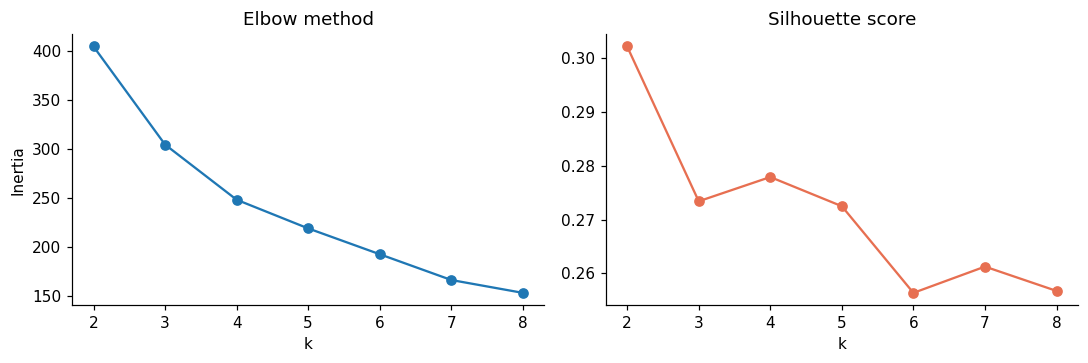

Chosen k: 2


In [3]:
CLUSTER_FEATURES = ["share_late", "mean_delay", "p90_delay",
                    "peak_effect", "rain_effect", "share_long_distance"]
X = StandardScaler().fit_transform(profile[CLUSTER_FEATURES])

ks = range(2, 9)
inertia, silhouette = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=config.RANDOM_STATE).fit(X)
    inertia.append(km.inertia_); silhouette.append(silhouette_score(X, km.labels_))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].plot(list(ks), inertia, marker="o"); axes[0].set_title("Elbow method"); axes[0].set_xlabel("k"); axes[0].set_ylabel("Inertia")
axes[1].plot(list(ks), silhouette, marker="o", color="#e76f51"); axes[1].set_title("Silhouette score"); axes[1].set_xlabel("k")
plt.tight_layout(); plt.savefig(config.OUTPUT_DIR / "05_kmeans_choice_of_k.png", dpi=200); plt.show()

K = list(ks)[int(np.argmax(silhouette))]   # adjust manually if needed (consider the elbow)
print("Chosen k:", K)
km = KMeans(n_clusters=K, n_init=20, random_state=config.RANDOM_STATE).fit(X)
profile["cluster"] = km.labels_

In [4]:
cluster_profile = profile.groupby("cluster").agg(
    stations=("bpuic", "size"), arrivals=("arrivals", "sum"),
    **{f: (f, "mean") for f in CLUSTER_FEATURES})
display(cluster_profile.round(3))
for c in sorted(profile["cluster"].unique()):
    names = profile[profile["cluster"] == c].sort_values("arrivals", ascending=False)["station"].head(6).tolist()
    print(f"Cluster {c}: {', '.join(names)}")
display(pd.crosstab(profile["cluster"], profile["region"]))
cluster_profile.round(3).to_csv(config.OUTPUT_DIR / "05_cluster_profiles.csv")

,stations,arrivals,share_late,mean_delay,p90_delay,peak_effect,rain_effect,share_long_distance
cluster,,,,,,,,
0,36,165854.0,0.087,0.970,2.756,0.014,0.040,0.299
1,64,234281.0,0.044,0.558,1.929,0.026,0.006,0.138


Cluster 0: Zürich HB, Zürich Hardbrücke, Olten, Lausanne, Aarau, Renens VD
Cluster 1: Bern, Zürich Oerlikon, Zürich Stadelhofen, Winterthur, St. Gallen, Worblaufen


region,German-speaking,Romandy,Ticino
cluster,,,
0,22,11,3
1,56,6,2


## 2. Geodata: maps

In [5]:
import folium

def colour(value, vmin, vmax):
    x = min(max((value - vmin) / (vmax - vmin + 1e-9), 0), 1)
    r, g = int(255 * x), int(180 * (1 - x))
    return f"#{r:02x}{g:02x}40"

vmin, vmax = profile["share_late"].quantile([0.05, 0.95])
punctuality_map = folium.Map(location=[46.8, 8.2], zoom_start=8, tiles="OpenStreetMap")
for _, r in profile.iterrows():
    folium.CircleMarker(
        location=[r["lat"], r["lon"]], radius=3 + 12 * np.sqrt(r["arrivals"] / profile["arrivals"].max()),
        color=colour(r["share_late"], vmin, vmax), fill=True, fill_opacity=0.85,
        tooltip=f"{r['station']}: {r['share_late']:.1%} late ({int(r['arrivals']):,} arrivals)",
    ).add_to(punctuality_map)
punctuality_map.save(config.OUTPUT_DIR / "05_map_punctuality.html")
punctuality_map

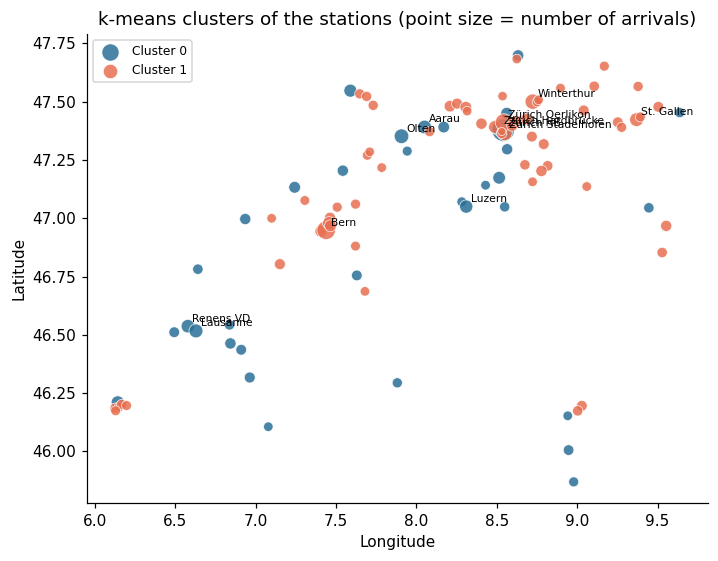

In [6]:
palette = ["#2a6f97", "#e76f51", "#2a9d8f", "#e9c46a", "#6a4c93", "#c1121f", "#8ecae6", "#264653"]
cluster_map = folium.Map(location=[46.8, 8.2], zoom_start=8, tiles="OpenStreetMap")
for _, r in profile.iterrows():
    folium.CircleMarker(location=[r["lat"], r["lon"]], radius=6, color=palette[int(r["cluster"]) % 8],
                        fill=True, fill_opacity=0.9, tooltip=f"{r['station']} – cluster {int(r['cluster'])}").add_to(cluster_map)
cluster_map.save(config.OUTPUT_DIR / "05_map_clusters.html")

# static version for the slides
fig, ax = plt.subplots(figsize=(8, 5.2))
for c in sorted(profile["cluster"].unique()):
    p = profile[profile["cluster"] == c]
    ax.scatter(p["lon"], p["lat"], s=15 + 200 * p["arrivals"] / profile["arrivals"].max(),
               color=palette[c % 8], label=f"Cluster {c}", alpha=0.85, edgecolor="white", lw=0.5)
for _, r in profile.nlargest(12, "arrivals").iterrows():
    ax.annotate(r["station"], (r["lon"], r["lat"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude"); ax.set_aspect(1.45)
ax.set_title("k-means clusters of the stations (point size = number of arrivals)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(config.OUTPUT_DIR / "05_cluster_map_static.png", dpi=200); plt.show()
cluster_map

## 3. Statistical tests
With very large samples even small differences become significant → we also report **effect sizes** (Cramér's V, η²).

In [7]:
print("Chi-squared test: region × late")
tab = pd.crosstab(df["region"], df["late"])
chi2, p, dof, _ = stats.chi2_contingency(tab)
cramers_v = np.sqrt(chi2 / (tab.values.sum() * (min(tab.shape) - 1)))
display(tab)
print(f"  Chi² = {chi2:,.1f}, df = {dof}, p = {p:.3g}, Cramér's V = {cramers_v:.3f}")

print("\nChi-squared test: time window × late")
tab2 = pd.crosstab(df["time_window"], df["late"])
chi2b, pb, dofb, _ = stats.chi2_contingency(tab2)
print(f"  Chi² = {chi2b:,.1f}, df = {dofb}, p = {pb:.3g}, Cramér's V = {np.sqrt(chi2b / tab2.values.sum()):.3f}")

Chi-squared test: region × late


late,0,1
region,,
German-speaking,302914,18547
Romandy,57943,5593
Ticino,14066,1072


  Chi² = 843.0, df = 2, p = 8.79e-184, Cramér's V = 0.046

Chi-squared test: time window × late
  Chi² = 799.2, df = 1, p = 8.21e-176, Cramér's V = 0.045


In [8]:
print("ANOVA: mean arrival delay by region")
groups = [g["arr_delay_min"].values for _, g in df.groupby("region") if len(g) > 30]
f, p_anova = stats.f_oneway(*groups)
ss_between = sum(len(g) * (g.mean() - df["arr_delay_min"].mean()) ** 2 for g in groups)
eta2 = ss_between / ((df["arr_delay_min"] - df["arr_delay_min"].mean()) ** 2).sum()
print(f"  F = {f:,.2f}, p = {p_anova:.3g}, η² = {eta2:.4f}")
h, p_kw = stats.kruskal(*groups)
print(f"  Kruskal-Wallis (robust, as delays are skewed): H = {h:,.2f}, p = {p_kw:.3g}")
display(df.groupby("region")["arr_delay_min"].agg(["count", "mean", "median", "std"]).round(2))

ANOVA: mean arrival delay by region
  F = 19.90, p = 2.27e-09, η² = 0.0001


  Kruskal-Wallis (robust, as delays are skewed): H = 2,075.56, p = 0


,count,mean,median,std
region,,,,
German-speaking,321461,0.75,0.43,2.47
Romandy,63536,0.77,0.17,3.43
Ticino,15138,0.89,0.28,3.56


In [9]:
print("Correlation: precipitation vs. share late (aggregated per station and hour)")
hourly = (df.assign(hour_ts=pd.to_datetime(df["arr_scheduled"]).dt.floor("h"))
            .groupby(["bpuic", "hour_ts"])
            .agg(share=("late", "mean"), precipitation=("precipitation", "first"), n=("late", "size"))
            .query("n >= 3"))
r_p, p_p = stats.pearsonr(hourly["precipitation"], hourly["share"])
r_s, p_s = stats.spearmanr(hourly["precipitation"], hourly["share"])
print(f"  n = {len(hourly):,} station-hours")
print(f"  Pearson r = {r_p:.3f} (p = {p_p:.3g}) | Spearman ρ = {r_s:.3f} (p = {p_s:.3g})")

Correlation: precipitation vs. share late (aggregated per station and hour)


  n = 26,552 station-hours
  Pearson r = 0.084 (p = 2.02e-42) | Spearman ρ = 0.080 (p = 1.02e-38)


## 4. Interpretation

*(Real data)*
- **Clusters (k = 2, chosen by silhouette score):** cluster 0 (36 stations, e.g. Zürich HB, Olten, Lausanne, Aarau) contains the *delay-prone hubs*: 8.7% late, more long-distance traffic (30%) and a higher sensitivity to rain. Cluster 1 (64 stations, e.g. Bern, Oerlikon, Winterthur, St. Gallen) is *punctual* with 4.4% and mostly S-Bahn. **11 of 17 stations in Romandy** are in the delay-prone cluster, but only 22 of 78 in German-speaking Switzerland.
- **Map:** almost all of the least punctual stations are in the canton of Vaud (Yverdon 15.5%, Palézieux 13.6%, Lausanne 12.2%, Renens, Morges, Vevey, Montreux, Aigle), plus Basel SBB (12.1%) and Biel (10.0%).
- **Tests:** because of the very large sample all differences are highly significant (p < 0.001), but the **effect sizes are small**: chi² region × late: Cramér's V = 0.046; time window × late: V = 0.045; ANOVA mean delay by region: η² = 0.0001 (the Kruskal-Wallis test robustly confirms the differences). Correlation precipitation ↔ share late per station-hour: r = 0.08 (weakly positive). → Statistically confirmed, but in practice region, time of day and rain each explain only a small part of the delays.